# Práctica de detección de objetos

### **Grupo:** N — **Integrantes:** Lucas Amado Oseira y María Lestón Geada
##### **Dataset:** Lettuce Pallets (`Francesco/lettuce-pallets`)
##### **Detectores:** Cascade R-CNN (Detectron2) y SSD300-VGG16 (Torchvision), ambos preentrenados en MS COCO

## Cómo usar este cuaderno y resumen de decisiones

El cuaderno está pensado para ejecutarse de arriba abajo en Kaggle, con la GPU y el acceso a Internet activados en los ajustes. Primero se instalan las dependencias y se configura el entorno; después se cargan y limpian los datos, se analiza el dataset y se define la infraestructura común de evaluación; por último se entrena y evalúa el baseline de cada detector (SSD300 y Cascade R-CNN) y se comparan en una misma sección de resultados. Todo lo que se genera (checkpoints, predicciones, figuras y `results.csv`) se guarda en `/kaggle/working/work`. Si un entrenamiento ya existe en esa carpeta se reutiliza y solo se recalcula la evaluación, de modo que `results.csv` va acumulando los resultados de todos los experimentos.

Las decisiones de diseño más importantes son las siguientes. Hemos eliminado la clase `lettuce` (id 0), que es la categoría «padre» de Roboflow, no tiene ninguna anotación y obligaría a los modelos a trabajar con 6 clases cuando el guion habla de 5. Seguimos un protocolo de datos estricto: se entrena con *train*, las decisiones se toman con *val* y la cifra que se reporta es la de *test*, para no ajustar las decisiones al conjunto final. El baseline parte de los pesos de COCO, no incluye ningún aumento de datos añadido por nosotros y usa una única tasa de aprendizaje por detector, de forma que cualquier mejora posterior pueda atribuirse a un cambio concreto. Por último, los dos detectores se evalúan con el mismo código (`evaluate_coco`), los mismos umbrales de inferencia y el mismo protocolo de medida de tiempos, y sus resultados se imprimen siempre con el mismo formato para que la comparación sea justa.

## 1. Imports y configuración del entorno

Ejecutamos esta celda una vez por sesión de Kaggle (acelerador **GPU** e **Internet** activados en *Settings*). Detectron2 se compila desde el repositorio oficial (tarda varios minutos).
Si la sesión pide reiniciar el kernel, lo reiniciamos y continuamos desde la celda de imports.

In [21]:
# pycocotools ya viene en Kaggle; por si acaso
!pip -q install pycocotools

# Detectron2 se compila desde el repositorio (tarda varios minutos); se omite si ya está instalado
!python -c "import detectron2" 2>/dev/null || pip -q install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

Importamos las librerías necesarias para realizar la práctica.

In [22]:
import os, sys, io, json, time, math, copy, random, tarfile, contextlib, gc, importlib.util
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from datasets import load_dataset

import torch
import torchvision
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Importamos las librerías de pycocotools para la evaluación del modelo y el manejo del dataset COCO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Importamos las librerías de Detectron2 para la configuración, entrenamiento y evaluación del modelo
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.evaluation import COCOEvaluator
from detectron2.data import (DatasetCatalog, MetadataCatalog, DatasetMapper,
                                build_detection_train_loader, transforms as T)
from detectron2.data.datasets import register_coco_instances

La práctica se ejecuta en Kaggle. Definimos las constantes: rutas de trabajo (`/kaggle/working`), el origen del dataset y los parámetros de inferencia comunes a ambos detectores.
Además, fijaremos una semilla que nos garantice la reproducibilidad de los resultados.

**Origen del dataset** (se prueba en este orden): 1) datos ya preparados en `data/raw`; 2) carpetas Roboflow (`train/`, `valid/`, `test/`) o un `dataset.tar.gz` añadidos como *Input* del notebook;
3) descarga desde Hugging Face (`Francesco/lettuce-pallets`, requiere Internet) y exportación al mismo formato Roboflow, de modo que **la limpieza posterior es idéntica en los tres casos**.

In [23]:
SEED = 2710
DATASET_NAME = "lettuce-pallets"
HF_DATASET = "Francesco/lettuce-pallets"   # solo se usa si no hay dataset en /kaggle/input

IN_KAGGLE = Path("/kaggle/working").exists()
KAGGLE_INPUT = Path("/kaggle/input")
ROOT_DIR = Path("/kaggle/working") if IN_KAGGLE else Path(".")   # en local se usa el directorio actual
WORK_DIR = ROOT_DIR / "work"    # checkpoints, predicciones, figuras y results.csv
DATA_DIR = ROOT_DIR / "data"    # datos extraídos y limpios

PRETRAINED = True # pesos preentrenados en COCO

# Parámetros de inferencia comunes a ambos detectores
SCORE_THRESH_EVAL = 0.001
NMS_IOU = 0.5
MAX_DETS = 300

SPLITS = ("train", "val", "test")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| Kaggle:", IN_KAGGLE)

Device: cuda | Kaggle: True


In [24]:
# Fijamos todas las semillas para asegurar la reproducibilidad de los experimentos
def seed_everything(seed=SEED, deterministic=True):
    """Fija todas las semillas. 'deterministic' hace cuDNN determinista (algo más lento)."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# Función para fijar la semilla de los workers del DataLoader, si no el aumento de datos no es reproducible
def seed_worker(worker_id):
    np.random.seed(SEED + worker_id)
    random.seed(SEED + worker_id)

# Creamos un generador de números aleatorios para el DataLoader, que se utilizará para inicializar los workers y garantizar la reproducibilidad
def make_generator(seed=SEED):
    return torch.Generator().manual_seed(seed)

seed_everything() # Fijamos la semilla

# Creamos los subdirectorios necesarios para almacenar los resultados del entrenamiento y la evaluación
for sub in ("ckpt", "preds", "figs", "d2"):
    (WORK_DIR / sub).mkdir(parents=True, exist_ok=True)

# Creamos los subdirectorios necesarios para almacenar los datos limpios y procesados del dataset
DATA_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR = DATA_DIR / "clean" # directorio para almacenar los datos limpios y procesados del dataset
CLEAN_DIR.mkdir(exist_ok=True)
print("WORK_DIR:", WORK_DIR.resolve())

WORK_DIR: /kaggle/working/work


## 2. Datos: extracción, limpieza y formato unificado

Comenzaremos a tratar los datos: localizamos el dataset (ver orden de búsqueda más arriba) y el JSON y la carpeta de imágenes de cada split. Localizamos los splits por el nombre exacto de la carpeta (`train`, `valid`, `test`) de forma robusta.

Con la función `export_hf` descargamos el dataset de Hugging Face mediante `load_dataset` y lo escribimos en disco con el mismo formato que Roboflow, de modo que el resto del cuaderno funcione igual con independencia del origen de los datos. Los nombres de los splits se normalizan con el diccionario `SPLIT_DIR_ALIASES` (por ejemplo, `validation` pasa a `valid`). Cada imagen se guarda como `00000.jpg`, `00001.jpg`... y su identificador es simplemente su índice dentro del split; así, los nombres de archivo y los ids son únicos y no dependemos del campo `image_id` del dataset original, que podía repetirse entre splits.

Las anotaciones se guardan en formato COCO, con `bbox = [x, y, w, h]` (esquina superior izquierda, ancho y alto). Guardamos también el área (`w·h`), que COCO usa para clasificar los objetos en pequeños, medianos y grandes durante la evaluación, y `iscrowd = 0`, porque cada anotación es un objeto individual y no una multitud:

```python
{"id": n, "image_id": idx, "category_id": int(cat),
 "bbox": [x, y, w, h], "area": w*h, "iscrowd": 0}
```

En esta fase conservamos todas las categorías originales, incluida `lettuce` con id 0; se elimina más adelante, durante la limpieza.

In [25]:
SPLIT_DIR_ALIASES = {"train": "train", "valid": "val", "validation": "val", "val": "val", "test": "test"}

# Extraemos el tar.gz si el destino está vacío
def extract_tar(tar_path, dest):
    """Extrae el tar.gz si el destino está vacío."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    if not any(dest.iterdir()):
        with tarfile.open(tar_path, "r:*") as tar:
            try: tar.extractall(dest, filter="data")
            except TypeError: tar.extractall(dest)
    return dest

# Localizamos los splits de entrenamiento, validación y test en el dataset extraído
def locate_raw_splits(root):
    raw = {}
    for js in Path(root).rglob("*.json"):
        key = SPLIT_DIR_ALIASES.get(js.parent.name.lower())
        if key and key not in raw:
            raw[key] = {"json": js, "images": js.parent} # en Roboflow, las imágenes están junto al JSON
    missing = [s for s in SPLITS if s not in raw]
    assert not missing, f"Faltan splits: {missing}"
    return raw

def find_tar_in_input():
    if not KAGGLE_INPUT.exists(): return None
    for pat in ("*.tar.gz", "*.tgz", "*.tar"):
        found = sorted(KAGGLE_INPUT.rglob(pat))
        if found: return found[0]
    return None

def export_hf(dest):
    """Descarga el dataset de Hugging Face y lo escribe como Roboflow: <split>/{imágenes, _annotations.coco.json}.
    Se conservan TODAS las categorías originales (incluida 'lettuce', id 0) para que build_clean_coco haga el mismo trabajo."""

    #Descargamos en memoria el dataset de Hugging Face y lo escribimos en el directorio de destino como Roboflow: <split>/{imágenes, _annotations.coco.json}.
    hf_ds = load_dataset(HF_DATASET)
    # Mapeamos los nombres internos de los splits con  los nombres de directorio que queremos usar en el destino
    dir_names = {"train": "train", "val": "valid", "test": "test"}
    # Accedemos al primer split disponible e inspeccionamos el esquema (features) de categoría de objects para tener los nombres de las clases
    feat = hf_ds[next(iter(hf_ds.keys()))].features["objects"]["category"]
    # En caso de que la columna de categoríais esté eun un contenedor de tipo Sequence/List, obtenemos el feature ClassLabel subyacente
    feat = getattr(feat, "feature", feat)                       # Sequence/List(ClassLabel) -> ClassLabel
    # Si el feature es de tipo ClassLabel, obtenemos los nombres de las clases; si no, dejamos names como None
    names = list(feat.names) if getattr(feat, "names", None) else None
    # Inicializamos un conjunto para almacenar las categorías observadas en el dataset
    observed = set()

    # Recorremos cada split del dataset
    for split_name, ds in hf_ds.items():
        # Normalizamos el nombre del split a minúsculas y determinamos la clave correspondiente en dir_names
        s = split_name.lower()
        key = "train" if s == "train" else "val" if "val" in s else "test" if "test" in s else None
        if key is None: continue
        out = Path(dest) / dir_names[key]
        out.mkdir(parents=True, exist_ok=True)
        # Inicializamos listas para almacenar la información de las imágenes y anotaciones
        images, anns = [], []
        # Iteramos sobre cada fila del split del dataset convirtiendo las imágenes a RGB y guardándolas en el directorio correspondiente, mientras recopilamos la información de las anotaciones
        for idx, row in enumerate(ds):
            img = row["image"].convert("RGB")
            fn = f"{idx:05d}.jpg"; img.save(out / fn, quality=95)
            images.append({"id": idx, "file_name": fn, "width": img.width, "height": img.height})
            objs = row["objects"]
            # Emparejamos cada bounding box con su categoría correspondiente y agregamos la información a la lista de anotaciones, mientras registramos las categorías observadas
            for bbox, cat in zip(objs["bbox"], objs["category"]):
                x, y, w, h = map(float, bbox); observed.add(int(cat))
                anns.append({"id": len(anns) + 1, "image_id": idx, "category_id": int(cat),
                             "bbox": [x, y, w, h], "area": w * h, "iscrowd": 0})
        # Escribimos el archivo _annotations.coco.json para el split actual, incluyendo las imágenes y anotaciones recopiladas
        (out / "_annotations.coco.json").write_text(json.dumps({"images": images, "annotations": anns, "categories": []}))
    # Actualizamos el archivo _annotations.coco.json para cada split, incluyendo las categorías
    cat_ids = range(len(names)) if names else sorted(observed)
    cats = [{"id": i, "name": names[i] if names else str(i)} for i in cat_ids]
    for d in dir_names.values():
        p = Path(dest) / d / "_annotations.coco.json"
        j = json.loads(p.read_text()); j["categories"] = cats; p.write_text(json.dumps(j))
    return dest

raw_root = DATA_DIR / "raw"
if not raw_root.exists() or not any(raw_root.iterdir()):
    print("Preparando datos RAW...")
    RAW = locate_raw_splits(export_hf(raw_root))
for s in SPLITS: print(f"{s}: {RAW[s]['json']}")

train: /kaggle/working/data/raw/train/_annotations.coco.json
val: /kaggle/working/data/raw/valid/_annotations.coco.json
test: /kaggle/working/data/raw/test/_annotations.coco.json


A continuación, cargamos el dataset de entrenamiento COCO y mostramos información sobre las distintas categorías de lechuga y las anotaciones existentes para cada imagen.

In [26]:
# Información del dataset ANTES de la limpieza (lee el JSON original de Roboflow)
raw_train = COCO(str(RAW["train"]["json"]))
raw_cats = sorted(raw_train.loadCats(raw_train.getCatIds()), key=lambda x: x["id"])

print("\nCategorías COCO (originales):", [(c["id"], c["name"]) for c in raw_cats])
print(f"Total imágenes de entrenamiento: {len(raw_train.getImgIds())}")
print(f"Número de anotaciones train: {len(raw_train.getAnnIds())}")

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!

Categorías COCO (originales): [(0, 'lettuce'), (1, 'Ready'), (2, 'empty_pod'), (3, 'germination'), (4, 'pod'), (5, 'young')]
Total imágenes de entrenamiento: 1060
Número de anotaciones train: 13812


En principio vemos que existen 6 categorías distintas: *'lettuce', 'Ready', 'empty_pod', 'germination', 'pod'* y *'young'*, repartidas entre 1060 imágenes de entrenamiento y con un total de 13812 anotaciones.

Mostramos las anotaciones por categoría.

In [27]:
for c in raw_cats:
    n = len(raw_train.getAnnIds(catIds=[c["id"]]))
    print(f"  id {c['id']}: {c['name']:11s} -> {n} anotaciones")

  id 0: lettuce     -> 0 anotaciones
  id 1: Ready       -> 1387 anotaciones
  id 2: empty_pod   -> 1100 anotaciones
  id 3: germination -> 4651 anotaciones
  id 4: pod         -> 2531 anotaciones
  id 5: young       -> 4143 anotaciones


Comprobamos que todas las categorías tienen anotaciones menos `lettuce`.

## Limpieza de las anotaciones

A partir del análisis anterior generamos un JSON limpio por split aplicando cuatro decisiones.

La primera es eliminar la categoría `lettuce` (id 0). En Roboflow actúa como categoría «padre» de las demás y no tiene anotaciones propias, de modo que mantenerla habría añadido una clase fantasma que nunca aparece y habría dejado a los modelos con 6 clases en lugar de las 5 reales. La segunda es renumerar las clases de 1 a 5: en torchvision la etiqueta 0 está reservada al fondo, y con identificadores contiguos desde 1 la etiqueta del modelo coincide directamente con el `category_id`, así que no hace falta ninguna conversión ni hay riesgo de desplazar las clases al evaluar.

La tercera decisión es recortar las cajas a los límites de la imagen y descartar las degeneradas, es decir, las de ancho o alto menor de 1 px, porque una caja de tamaño nulo provoca errores y pérdidas `NaN` durante el entrenamiento. Esto afecta a una única anotación de *test* y a ninguna de *train* ni *val*. Por último, conservamos en el JSON las imágenes sin objetos: se utilizan en la evaluación (donde cualquier detección sobre ellas cuenta como falso positivo), aunque Detectron2 las ignora al entrenar.

In [28]:
def build_clean_coco(raw, out_dir):
    """Genera un JSON COCO limpio por split. Devuelve (CLEAN, class_names, class_ids)."""
    # Creamos el directorio de salida si no existe
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Leemos el JSON de entrenamiento original y obtenemos los nombres de las categorías y los IDs utilizados
    train = json.loads(Path(raw["train"]["json"]).read_text())
    old_names = {c["id"]: c["name"] for c in train["categories"]}
    used_ids = sorted({a["category_id"] for a in train["annotations"]})
    dropped = [n for i, n in old_names.items() if i not in used_ids] # categorías descartadas
    print("Categorías descartadas (sin anotaciones en train):", dropped)

    # Creamos un diccionario que mapea los nombres de las categorías a nuevos IDs consecutivos (1..K) para las categorías utilizadas
    name2new = {old_names[i]: n + 1 for n, i in enumerate(used_ids)}

    # Iteramos sobre cada split y generamos un nuevo JSON COCO limpio
    # Descartamos anotaciones de categorías no utilizadas y cajas degeneradas
    clean = {}
    for split in SPLITS:
        d = json.loads(Path(raw[split]["json"]).read_text())
        id2name = {c["id"]: c["name"] for c in d["categories"]}
        imgs = {im["id"]: im for im in d["images"]}
        new_anns, stats = [], Counter()
        
        for a in d["annotations"]:
            name = id2name.get(a["category_id"])
            
            # Descartamos cajas degeneradas (cajas con ancho o alto menor que 1 píxel)
            im = imgs[a["image_id"]]; x, y, w, h = a["bbox"]
            x1, y1 = max(0.0, x), max(0.0, y)
            x2, y2 = min(float(im["width"]), x + w), min(float(im["height"]), y + h)
            if x2 - x1 < 1 or y2 - y1 < 1:
                stats["caja_degenerada"] += 1
                continue
            
            # Creamos la nueva anotación con el nuevo ID de categoría y la caja ajustada
            new_anns.append({"id": len(new_anns) + 1, "image_id": a["image_id"],
                             "category_id": name2new[name], "bbox": [x1, y1, x2 - x1, y2 - y1],
                             "area": (x2 - x1) * (y2 - y1), "iscrowd": 0})
        
        # Guardamos el nuevo JSON COCO limpio para el split actual
        out = {"images": d["images"], "annotations": new_anns,
               "categories": [{"id": i, "name": n} for n, i in name2new.items()]}
        
        # Guardamos el JSON limpio en el directorio de salida y almacenamos la información del split en el diccionario 'clean'
        p = out_dir / f"{split}_clean.json"; p.write_text(json.dumps(out))
        clean[split] = {"json": p, "images": Path(raw[split]["images"])}
        print(f"{split:5s}: {len(d['images'])} imgs | {len(d['annotations'])} -> {len(new_anns)} anotaciones | descartes: {dict(stats)}")
    names = list(name2new.keys())
    ids = list(name2new.values())
    return clean, names, ids

CLEAN, CLASS_NAMES, CLASS_IDS = build_clean_coco(RAW, CLEAN_DIR)
K = len(CLASS_NAMES) # nº de clases reales
# Creamos un diccionario que mapea los IDs de las clases a sus índices
CID2IDX = {c: i for i, c in enumerate(CLASS_IDS)}
print(f"\nK = {K} clases:", dict(zip(CLASS_IDS, CLASS_NAMES)))

# Creamos un diccionario que mapea los splits a sus objetos COCO correspondientes para facilitar la evaluación
COCO_GT = {s: COCO(str(CLEAN[s]["json"])) for s in SPLITS}

Categorías descartadas (sin anotaciones en train): ['lettuce']
train: 1060 imgs | 13812 -> 13812 anotaciones | descartes: {}
val  : 151 imgs | 2042 -> 2042 anotaciones | descartes: {}
test : 299 imgs | 3867 -> 3866 anotaciones | descartes: {'caja_degenerada': 1}

K = 5 clases: {1: 'Ready', 2: 'empty_pod', 3: 'germination', 4: 'pod', 5: 'young'}
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


## 3. Análisis exploratorio del dataset

## 3. Análisis exploratorio del dataset

Antes de proponer ninguna mejora medimos las características del dataset que más condicionan el diseño del experimento: el reparto de clases, el número de objetos por imagen y, sobre todo, el tamaño de los objetos. Es además el análisis que pide el guion para el primer bloque de la exposición.

El reparto de clases nos dice si hay categorías raras que justifiquen un muestreo balanceado o una pérdida ponderada. El tamaño de los objetos es especialmente relevante para SSD300, que reescala todas las imágenes a 300×300 píxeles y pierde por tanto detalle en los objetos pequeños, así que calculamos también el tamaño efectivo de cada objeto tras ese reescalado. Por último, revisamos algunas imágenes con sus anotaciones para identificar a simple vista los retos visuales (iluminación, oclusiones, parecido entre clases), que son los que deben orientar las estrategias de mejora, incluido qué tipo de aumento de datos tiene sentido aplicar.

In [29]:
# Creamos un DataFrame con las anotaciones de todos los splits
# Incluimos información sobre el tamaño y la relación de aspecto de cada objeto
def annotations_dataframe(coco, split):
    rows = []
    for a in coco.anns.values():
        im = coco.imgs[a["image_id"]]

        # Calculamos el área de la caja delimitadora
        x, y, w, h = a["bbox"]
        area = w * h

        # Agregamos la información al DataFrame
        rows.append({"split": split, "image_id": a["image_id"],
                     "cls": CLASS_NAMES[CID2IDX[a["category_id"]]], # nombre de la clase
                     "w": w, "h": h, "area": area, # área de la caja delimitadora
                     "sqrt_area": math.sqrt(area), # raíz cuadrada del área de la caja delimitadora
                     "rel_size": math.sqrt(area / (im["width"] * im["height"])), # tamaño relativo del objeto respecto al tamaño de la imagen
                     "aspect": w / h}) # relación entre el ancho y el alto de la caja delimitadora
    df = pd.DataFrame(rows)
    # Clasificamos los objetos en categorías de tamaño: pequeño, mediano y grande según el área de la caja delimitadora
    # Los límites de las categorías se establecen en 32^2 y 96^2 píxeles cuadrados, según la convención de COCO
    df["size_cat"] = pd.cut(df["area"], [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
    return df

# Creamos el DataFrame con las anotaciones para todos los splits
ANN_DF = pd.concat([annotations_dataframe(COCO_GT[s], s) for s in SPLITS], ignore_index=True)

# Mostramos un resumen de las imágenes y anotaciones por split
print("Imágenes y anotaciones por split:")
summary = []
for s in SPLITS:
    c = COCO_GT[s]
    per_img = Counter(a["image_id"] for a in c.anns.values()) # contamos el número de anotaciones por imagen
    n_img = len(c.imgs)
    n_empty = sum(1 for i in c.imgs if per_img.get(i, 0) == 0) # contamos el número de imágenes sin anotaciones
    summary.append({"split": s, "imágenes": n_img, "anotaciones": len(c.anns), "imgs_sin_objetos": n_empty,
                    "objs/img media": round(len(c.anns) / n_img, 1), # número medio de objetos por imagen
                    "objs/img máx": max(per_img.values())}) # número máximo de objetos en una imagen
display(pd.DataFrame(summary).set_index("split"))

# Mostramos un resumen de las anotaciones por clase y split
print("\nAnotaciones por clase y split:")
class_counts = ANN_DF.pivot_table(index="cls", columns="split", values="area", aggfunc="count").reindex(CLASS_NAMES)[list(SPLITS)]
class_counts["% train"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(1)
display(class_counts)

# Mostramos un resumen de la resolución de las imágenes en el dataset
print("\nResolución de las imágenes:")
display(pd.Series([(im["width"], im["height"]) for c in COCO_GT.values() for im in c.imgs.values()]).value_counts().head())

# SSD300 redimensiona todas las imágenes a 300x300
# Calculamos el tamaño efectivo del objeto en píxeles tras el reescalado a 300x300 píxeles
ANN_DF["px_ssd300"] = ANN_DF["rel_size"] * 300
tr = ANN_DF[ANN_DF.split == "train"]

# Mostramos un resumen de la distribución del tamaño de los objetos en el conjunto de entrenamiento
print("\nTamaño de objeto (train):", tr["size_cat"].value_counts(normalize=True).round(3).to_dict())

# Mostramos un resumen de la raíz cuadrada del área de los objetos en píxeles originales y sus cuantiles
print("sqrt(área) px originales, cuantiles:", tr["sqrt_area"].quantile([.05, .25, .5, .75, .95]).round(1).to_dict())

# Mostramos un resumen del porcentaje de objetos con tamaño efectivo menor a 16 píxeles en SSD300
# Los objetos muy pequeños pueden ser difíciles de detectar para el modelo SSD300
# Este porcentaje nos da una idea de cuántos objetos podrían ser problemáticos en términos de detección
print(f"% objetos con tamaño efectivo < 16 px en SSD300: {100*(tr['px_ssd300'] < 16).mean():.1f}%")

Imágenes y anotaciones por split:


,imágenes,anotaciones,imgs_sin_objetos,objs/img media,objs/img máx
split,,,,,
train,1060,13812,8,13.0,20
val,151,2042,1,13.5,21
test,299,3866,0,12.9,20



Anotaciones por clase y split:


split,train,val,test,% train
cls,,,,
Ready,1387,246,376,10.0
empty_pod,1100,182,311,8.0
germination,4651,631,1321,33.7
pod,2531,337,725,18.3
young,4143,646,1133,30.0



Resolución de las imágenes:


(640, 640)    1510
Name: count, dtype: int64


Tamaño de objeto (train): {'medium': 0.632, 'large': 0.368, 'small': 0.0}
sqrt(área) px originales, cuantiles: {0.05: 49.1, 0.25: 62.5, 0.5: 80.9, 0.75: 122.0, 0.95: 220.0}
% objetos con tamaño efectivo < 16 px en SSD300: 0.0%


Mostramos un resumen gráfico de las anotaciones por clase, el número de objetos por imagen, la distribución del tamaño de los objetos y la relación de aspecto de las cajas delimitadoras.

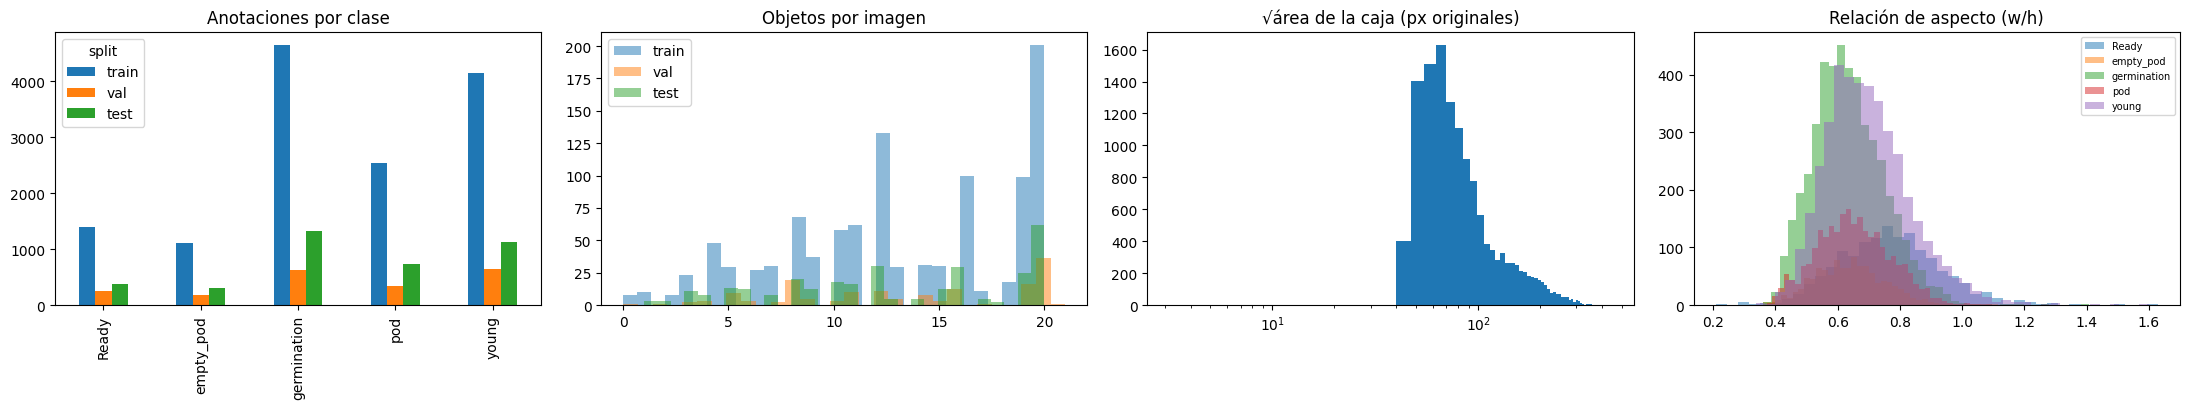

sqrt_area              px_ssd300             
               median   min    max    median   min    max
cls                                                      
Ready           187.2  58.0  444.5      87.8  27.2  208.4
empty_pod        74.2  42.5  135.9      34.8  19.9   63.7
germination      67.7  40.2  157.5      31.7  18.8   73.8
pod              64.1  38.9  242.0      30.0  18.3  113.4
young           123.4   3.2  355.3      57.8   1.5  166.6

In [30]:
fig, axs = plt.subplots(1, 4, figsize=(22, 4.2))

# Mostramos un gráfico de barras con el número de anotaciones por clase para cada split
class_counts[list(SPLITS)].plot.bar(ax=axs[0]); axs[0].set_title("Anotaciones por clase"); axs[0].set_xlabel("")

# Mostramos un histograma con el número de objetos por imagen para cada split
for s in SPLITS:
    cnt = Counter(a["image_id"] for a in COCO_GT[s].anns.values())
    axs[1].hist([cnt.get(i, 0) for i in COCO_GT[s].imgs], bins=30, alpha=.5, label=s)
axs[1].set_title("Objetos por imagen")
axs[1].legend()

# Mostramos un histograma que refleje la distribución del tamaño de los objetos
axs[2].hist(tr["sqrt_area"], bins=60)
axs[2].set_xscale("log")
axs[2].set_title("√área de la caja (px originales)")

# Mostramos un histograma con la relación de aspecto (ancho/alto) de los objetos por clase
for cls in CLASS_NAMES:
    axs[3].hist(tr[tr.cls == cls]["aspect"].clip(0, 4), bins=40, alpha=.5, label=cls)
axs[3].set_title("Relación de aspecto (w/h)")
axs[3].legend(fontsize=7)

plt.tight_layout()
plt.savefig(WORK_DIR / "figs" / "eda_overview.png", dpi=130)
plt.show()

# Mostramos el tamaño medio por clase para ver si hay clases sistemáticamente más pequeñas
# Esto puede ser relevante para la detección, ya que las clases más pequeñas pueden ser más difíciles de detectar para el modelo
display(tr.groupby("cls")[["sqrt_area", "px_ssd300"]].agg(["median", "min", "max"]).round(1).reindex(CLASS_NAMES))

Lo siguiente que haremos será mostrar algunas de las imágenes de entrenamiento con sus respectivos tamaños y anotaciones.

In [ ]:
# Creamos un array de colores para cada clase utilizando el colormap 'tab10' de Matplotlib
CLASS_COLORS = plt.cm.tab10(np.arange(K))

def draw_gt(coco, image_dir, image_ids, ncols=3):
    nrows = math.ceil(len(image_ids) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 6 * nrows)); axs = np.atleast_1d(axs).ravel()
    for ax in axs: ax.axis("off")
    for ax, iid in zip(axs, image_ids):
        info = coco.imgs[iid]
        ax.imshow(Image.open(Path(image_dir) / info["file_name"]).convert("RGB"))
        n_obj = 0
        for a in coco.loadAnns(coco.getAnnIds(imgIds=iid)):
            x, y, w, h = a["bbox"]
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=1.5, ec=CLASS_COLORS[CID2IDX[a["category_id"]]]))
            n_obj += 1
        ax.set_title(f"({info['width']}x{info['height']}) \n{n_obj} objetos anotados")
    handles = [patches.Patch(color=CLASS_COLORS[i], label=n) for i, n in enumerate(CLASS_NAMES)]
    fig.legend(handles=handles, loc="lower center", ncol=K)
    plt.tight_layout(); plt.show()

rng = random.Random(SEED)
draw_gt(COCO_GT["train"], CLEAN["train"]["images"], rng.sample(sorted(COCO_GT["train"].imgs), 3))

### Resumen del dataset (para la diapositiva de descripción)

El conjunto de entrenamiento tiene 1060 imágenes de 640×640 y 13812 anotaciones repartidas en cinco clases. La más frecuente es `germination` (33,7 % de las anotaciones de *train*), seguida de `young` (30,0 %), mientras que `empty_pod` (8,0 %) y `Ready` (10,0 %) son las minoritarias. La diferencia entre la clase más y menos frecuente es de algo más de 4 a 1: un desbalance moderado, no extremo.

Según el criterio de tamaño de COCO, el 63,2 % de los objetos son medianos y el 36,8 % grandes; prácticamente no hay objetos pequeños. Tras reescalar a 300×300, menos del 0,05 % de los objetos queda por debajo de 16 px, por lo que SSD300 no debería verse perjudicado de forma generalizada por el tamaño. Las excepciones son unas pocas cajas diminutas de la clase `young` (la menor mide apenas 3 px de lado) que posiblemente sean errores de anotación; son las que hacen que el mAP en objetos pequeños no sea informativo.

Hay una media de 13 objetos por imagen y un máximo de 20 en *train* y *test* (21 en *val*), con muchas imágenes que llegan justo a 20. El límite de 300 detecciones por imagen (`MAX_DETS`) es, por tanto, muy holgado.

En las imágenes que hemos revisado, el reto visual principal no es el tamaño sino el contexto. Las fotos están tomadas con un gran angular con distorsión de ojo de pez en un cultivo hidropónico con iluminación artificial cuyo tono varía bastante de una imagen a otra; alrededor de las bandejas hay vegetación de otras plantas que actúa como distractor, y las cajas de la clase `young` se solapan con frecuencia entre sí. Además, la vista no es estrictamente cenital: se aprecia una orientación y una perspectiva claras, de modo que un volteo vertical o un giro de 90° generaría escenas poco realistas. El volteo horizontal sí parece seguro, y el resto de transformaciones geométricas habrá que validarlas con los experimentos en lugar de darlas por buenas.

## 4. Infraestructura común: dataset, evaluación, tiempos y resultados

Partimos de los JSON **limpios** (5 clases, ids 1…5, cajas recortadas). Como los `category_id` son contiguos desde 1, la etiqueta que usa torchvision (0 = fondo) **coincide** con el `category_id` y no hace falta ninguna conversión.
Creamos el `Dataset` COCO para torchvision (SSD) y los `DataLoader`s; Detectron2 leerá los mismos JSON directamente.

In [32]:
assert CLASS_IDS == list(range(1, K + 1)), "Los ids deben ser 1..K para que label == category_id"

class CocoDetection(Dataset):
    """Dataset COCO para torchvision. Devuelve (imagen [0,1] CxHxW, target con cajas xyxy y etiquetas 1..K)."""
    def __init__(self, coco, image_dir, train=False):
        self.coco = coco
        self.image_dir = Path(image_dir)
        self.ids = sorted(coco.getImgIds())
        self.train = train

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        img_id = self.ids[index]
        info = self.coco.imgs[img_id]
        image = Image.open(self.image_dir / info["file_name"]).convert("RGB")
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))

        boxes  = [[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in anns]
        labels = [a["category_id"] for a in anns]

        image = TF.to_tensor(image)
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),  # reshape: imágenes sin objetos
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([img_id]),
        }

        if self.train:
            pass  # aquí se aplicaría el aumento de datos (fase de mejoras); el baseline no usa aumento

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Un Dataset por split, reutilizando los objetos COCO de ground truth ya cargados
DS = {s: CocoDetection(COCO_GT[s], CLEAN[s]["images"], train=(s == "train")) for s in SPLITS}

BATCH_SSD = 4
NUM_WORKERS = 2
train_loader = DataLoader(DS["train"], batch_size=BATCH_SSD, shuffle=True, collate_fn=collate_fn,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker, generator=make_generator())
val_loader = DataLoader(DS["val"], batch_size=BATCH_SSD, shuffle=False, collate_fn=collate_fn, num_workers=NUM_WORKERS)
print({s: len(DS[s]) for s in SPLITS})

{'train': 1060, 'val': 151, 'test': 299}


Definimos la evaluación común a ambos detectores. Recibe las predicciones en formato COCO y calcula el mAP@[.5:.95], el mAP@.5, el mAP@.75, el mAP por tamaño de objeto y el AP por clase con `COCOeval`, usando `maxDets = [1, 10, MAX_DETS]`. Las métricas se obtienen directamente del tensor de precisión que devuelve `COCOeval` y no de `ev.stats`: con un `maxDets` distinto del habitual (100), `summarize()` devuelve -1 para el mAP@[.5:.95], y era el valor que aparecía en la primera comparación de los baselines.

Junto a la evaluación definimos tres utilidades para que los dos detectores se traten exactamente igual. `print_metrics` imprime el informe de cada experimento siempre con el mismo formato. `evaluate_and_report` guarda las predicciones, evalúa, registra el resultado en `results.csv` y lanza ese informe. `time_inference` mide el tiempo de inferencia con un único protocolo: lote de una imagen, imágenes ya cargadas en memoria, calentamiento previo y sincronización de la GPU. Los tiempos se miden así, y no dentro del bucle de evaluación, porque ni la lectura de disco ni el tamaño del lote deben influir en una comparación de velocidad entre arquitecturas.

In [ ]:
METRIC_NAMES = ["mAP", "mAP50", "mAP75", "mAP_small", "mAP_medium", "mAP_large"]

def run_cocoeval(coco_gt, predictions, max_dets=MAX_DETS):
    """Ejecuta COCOeval (bbox) sin imprimir nada y devuelve el objeto con los tensores de precisión y recall."""
    with contextlib.redirect_stdout(io.StringIO()):
        coco_dt = coco_gt.loadRes(predictions)
        ev = COCOeval(coco_gt, coco_dt, "bbox")
        ev.params.maxDets = [1, 10, max_dets]
        ev.evaluate(); ev.accumulate()
    return ev

def _mean_valid(x):
    """Media de los valores válidos (COCOeval marca con -1 lo que no se puede calcular)."""
    x = np.asarray(x); x = x[x > -1]
    return float(x.mean()) if x.size else float("nan")

def evaluate_coco(coco_gt, predictions, max_dets=MAX_DETS):
    """Evaluación COCO (bbox) idéntica para SSD y Cascade R-CNN.
    Las métricas se calculan directamente sobre el tensor de precisión [T, R, K, A, M]. No usamos ev.stats[0]
    porque COCOeval.summarize() fija maxDets=100 para el mAP@[.5:.95] y, al haber definido maxDets=[1, 10, 300],
    ese valor salía como -1."""
    if not predictions:
        return {**{n: 0.0 for n in METRIC_NAMES}, **{f"AP_{c}": 0.0 for c in CLASS_NAMES}}
    ev = run_cocoeval(coco_gt, predictions, max_dets)
    prec = ev.eval["precision"][..., 2]               # [T, R, K, A]; M=2 -> max_dets
    iou = ev.params.iouThrs
    t50, t75 = int(np.argmin(np.abs(iou - 0.50))), int(np.argmin(np.abs(iou - 0.75)))
    m = {"mAP":        _mean_valid(prec[:, :, :, 0]),   # A=0: todas las áreas
         "mAP50":      _mean_valid(prec[t50, :, :, 0]),
         "mAP75":      _mean_valid(prec[t75, :, :, 0]),
         "mAP_small":  _mean_valid(prec[:, :, :, 1]),
         "mAP_medium": _mean_valid(prec[:, :, :, 2]),
         "mAP_large":  _mean_valid(prec[:, :, :, 3])}
    for k, cname in enumerate(CLASS_NAMES):           # los catIds de COCOeval van ordenados = CLASS_IDS
        m[f"AP_{cname}"] = _mean_valid(prec[:, :, k, 0])
    return m

RESULTS_CSV = WORK_DIR / "results.csv"

def log_result(exp, detector, split, metrics, train_time_s=float("nan"), infer_ms_img=float("nan"), params_m=float("nan")):
    """Añade (o sustituye) una fila en results.csv y devuelve la tabla completa."""
    row = {"exp": exp, "detector": detector, "split": split, **metrics,
           "train_min": round(train_time_s / 60, 1), "infer_ms_img": round(infer_ms_img, 1),
           "params_M": round(params_m, 1)}
    df = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()
    if len(df):
        df = df[~((df["exp"] == exp) & (df["split"] == split))]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        df = pd.DataFrame([row])
    df.to_csv(RESULTS_CSV, index=False)
    return df

def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()

def count_params(model):
    """Número de parámetros (en millones)."""
    return sum(p.numel() for p in model.parameters()) / 1e6

@torch.no_grad()
def time_inference(infer_fn, coco_gt, image_dir, n=100, warmup=10):
    """Tiempo medio de inferencia (ms/imagen) con el MISMO protocolo para cualquier detector:
    batch de 1 imagen, imágenes ya cargadas en memoria (no se mide la lectura de disco), calentamiento previo
    y sincronización de la GPU. Incluye el preprocesado, la red y el post-procesado (NMS) propios de cada detector.
    infer_fn recibe una imagen RGB uint8 (H, W, 3) como array de NumPy."""
    ids = sorted(coco_gt.imgs)[: n + warmup]
    imgs = [np.array(Image.open(Path(image_dir) / coco_gt.imgs[i]["file_name"]).convert("RGB")) for i in ids]
    for im in imgs[:warmup]:
        infer_fn(im)
    sync(); t0 = time.perf_counter()
    for im in imgs[warmup:]:
        infer_fn(im)
    sync()
    return 1000 * (time.perf_counter() - t0) / len(imgs[warmup:])

def print_metrics(exp, split, m, infer_ms=float("nan"), train_s=float("nan"), params_m=float("nan"), coco_gt=None):
    """Informe con el mismo formato para todos los detectores y experimentos."""
    line = "═" * 86
    n_small = sum(a["area"] < 32 ** 2 for a in coco_gt.anns.values()) if coco_gt is not None else None
    print(line); print(f" {exp}   |   split: {split}"); print(line)
    print(f" mAP@[.5:.95] = {m['mAP']:.3f}    mAP@.50 = {m['mAP50']:.3f}    mAP@.75 = {m['mAP75']:.3f}")
    nota = f"   (solo {n_small} objetos small en el GT: poco fiable)" if n_small is not None and n_small < 30 else ""
    print(f" Por tamaño:   small = {m['mAP_small']:.3f}    medium = {m['mAP_medium']:.3f}    large = {m['mAP_large']:.3f}{nota}")
    print(" AP por clase: " + "    ".join(f"{c} = {m[f'AP_{c}']:.3f}" for c in CLASS_NAMES))
    print(f" Coste:        {infer_ms:.1f} ms/img ({1000 / infer_ms:.1f} FPS)    entrenamiento = {train_s / 60:.1f} min    "
          f"{params_m:.1f} M parámetros\n")

def evaluate_and_report(tag, exp, detector, split, preds, infer_ms, train_s, params_m):
    """Guarda las predicciones, evalúa, registra en results.csv e imprime el informe común."""
    (WORK_DIR / "preds" / f"{tag}_{split}.json").write_text(json.dumps(preds))
    m = evaluate_coco(COCO_GT[split], preds)
    log_result(exp, detector, split, m, train_s, infer_ms, params_m)
    print_metrics(exp, split, m, infer_ms, train_s, params_m, COCO_GT[split])
    return m

## 5. Baseline SSD300 (torchvision)

Construimos el detector SSD300 con VGG16 como backbone, con pesos preentrenados en COCO, y sustituimos la cabeza de clasificación por una nueva para nuestras `K` clases (+1 de fondo).
Los umbrales de inferencia (`score_thresh`, `nms_thresh`, `detections_per_img`) son los comunes definidos en la configuración.

In [34]:
from torchvision.models.detection import ssd300_vgg16, SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd(pretrained=True):
    weights = SSD300_VGG16_Weights.COCO_V1 if pretrained else None
    model = ssd300_vgg16(weights=weights, score_thresh=SCORE_THRESH_EVAL,
                         nms_thresh=NMS_IOU, detections_per_img=MAX_DETS)

    # Canales de entrada de cada nivel de características y nº de anchors por posición
    in_channels = [layer.in_channels for layer in model.head.classification_head.module_list]
    num_anchors = model.anchor_generator.num_anchors_per_location()

    # Sustituimos la cabeza de clasificación para nuestras clases (+1 para fondo)
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels, num_anchors=num_anchors, num_classes=K + 1)
    return model

seed_everything()
ssd = build_ssd(PRETRAINED).to(DEVICE)
print("SSD300 preparado correctamente.")

Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 194MB/s] 


SSD300 preparado correctamente.


Entrenamos el baseline con SGD (momentum 0,9 y *weight decay* 5e-4) y una tasa de aprendizaje inicial de 0,002 que se divide entre 10 cada 5 épocas (`StepLR`), durante 15 épocas y sin aumento de datos. Es la receta clásica para SSD y la mantenemos sin tocar porque el baseline debe ser un punto de partida limpio frente al que medir cada mejora. Añadimos un recorte de gradiente (norma máxima 10) para evitar divergencias en las primeras épocas, cuando la cabeza de clasificación nueva todavía está inicializada al azar.

Como torchvision solo calcula la pérdida en modo entrenamiento, la pérdida de validación se obtiene pasando el modelo a `train()` sin actualizar los pesos. Nos quedamos con el checkpoint de menor pérdida de validación, y la decisión tiene efecto real: como se ve en la curva, a partir de la época 8 la pérdida de validación deja de bajar y sube ligeramente mientras la de entrenamiento sigue descendiendo, un indicio de sobreajuste incipiente. Si ya existe un checkpoint en `work/ckpt`, se reutiliza en lugar de volver a entrenar.

SSD epoch 1/15: train=3.8287 val=2.6130
SSD epoch 2/15: train=2.3274 val=2.2868
SSD epoch 3/15: train=1.9373 val=2.0726
SSD epoch 4/15: train=1.6602 val=1.9341
SSD epoch 5/15: train=1.4706 val=1.8812
SSD epoch 6/15: train=1.1368 val=1.7149
SSD epoch 7/15: train=1.0597 val=1.7008
SSD epoch 8/15: train=1.0240 val=1.6973
SSD epoch 9/15: train=0.9891 val=1.7033
SSD epoch 10/15: train=0.9614 val=1.7085
SSD epoch 11/15: train=0.9219 val=1.7143
SSD epoch 12/15: train=0.9180 val=1.7181
SSD epoch 13/15: train=0.9141 val=1.7197
SSD epoch 14/15: train=0.9138 val=1.7202
SSD epoch 15/15: train=0.9098 val=1.7219


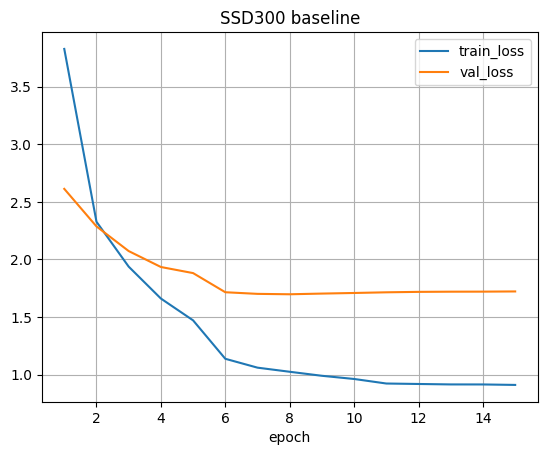

Tiempo de entrenamiento: 20.0 min


In [35]:
def train_one_epoch(model, loader, optimizer, device):
    model.train(); losses = []
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def mean_detection_loss(model, loader, device):
    # Torchvision solo calcula la loss en modo train; no se actualizan gradientes.
    model.train(); vals = []
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        vals.append(float(sum(model(images, targets).values()).cpu()))
    model.eval()
    return float(np.mean(vals))

EPOCHS_SSD = 15
LR_SSD = 0.002
SSD_CKPT = WORK_DIR / "ckpt" / "ssd300_baseline.pth"
SSD_HIST = WORK_DIR / "ckpt" / "ssd300_baseline_history.json"

if SSD_CKPT.exists() and SSD_HIST.exists():
    info = json.loads(SSD_HIST.read_text())
    history_ssd, ssd_train_time = info["history"], info["train_time_s"]
    ssd.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE))
    print(f"Checkpoint SSD reutilizado ({SSD_CKPT})")
else:
    optimizer = torch.optim.SGD([p for p in ssd.parameters() if p.requires_grad],
                                lr=LR_SSD, momentum=0.9, weight_decay=0.0005)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
    history_ssd, best_val = [], float("inf")
    sync(); t0 = time.time()
    for epoch in range(EPOCHS_SSD):
        tr = train_one_epoch(ssd, train_loader, optimizer, DEVICE)
        vl = mean_detection_loss(ssd, val_loader, DEVICE)
        scheduler.step()
        history_ssd.append({"epoch": epoch + 1, "train_loss": tr, "val_loss": vl})
        print(f"SSD epoch {epoch+1}/{EPOCHS_SSD}: train={tr:.4f} val={vl:.4f}")
        if vl < best_val:
            best_val = vl
            torch.save(ssd.state_dict(), SSD_CKPT)
    sync(); ssd_train_time = time.time() - t0
    SSD_HIST.write_text(json.dumps({"history": history_ssd, "train_time_s": ssd_train_time}))
    ssd.load_state_dict(torch.load(SSD_CKPT, map_location=DEVICE))   # nos quedamos con el mejor en val

ssd.eval()
pd.DataFrame(history_ssd).plot(x="epoch", y=["train_loss", "val_loss"], grid=True, title="SSD300 baseline")
plt.savefig(WORK_DIR / "figs" / "ssd_baseline_loss.png", dpi=130)
plt.show()
print(f"Tiempo de entrenamiento: {ssd_train_time/60:.1f} min")

Evaluamos SSD300 en *val* y *test* con la evaluación común. Las predicciones se calculan por lotes de 4 imágenes, algo que no afecta al resultado porque SSD reescala cada imagen a 300×300, y el tiempo de inferencia se mide aparte con `time_inference` para que sea comparable con el de Cascade R-CNN. El informe que se imprime tiene exactamente el mismo formato que el de Cascade R-CNN.

In [ ]:
@torch.no_grad()
def predict_ssd(model, dataset, batch_size=4):
    """Predicciones en formato COCO. El tiempo no se mide aquí sino con time_inference (protocolo común)."""
    model.eval(); preds = []
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS, collate_fn=collate_fn)
    for images, targets in loader:
        outputs = model([im.to(DEVICE) for im in images])
        for target, out in zip(targets, outputs):
            image_id = int(target["image_id"].item())
            for (x1, y1, x2, y2), score, label in zip(out["boxes"].cpu().tolist(),
                                                      out["scores"].cpu().tolist(),
                                                      out["labels"].cpu().tolist()):
                preds.append({"image_id": image_id, "category_id": CLASS_IDS[int(label) - 1],   # label 1..K
                              "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(score)})
    return preds

ssd.eval()
ssd_ms = time_inference(lambda im: ssd([TF.to_tensor(im).to(DEVICE)]), COCO_GT["test"], CLEAN["test"]["images"])
ssd_params = count_params(ssd)

for split in ("val", "test"):
    preds = predict_ssd(ssd, DS[split])
    evaluate_and_report("ssd300_baseline", "SSD300 baseline", "SSD300", split, preds, ssd_ms, ssd_train_time, ssd_params)

# Liberamos la GPU antes de entrenar Cascade R-CNN
del ssd; gc.collect(); torch.cuda.empty_cache()

## 6. Baseline Cascade R-CNN (Detectron2)

Registramos los JSON limpios en Detectron2 y configuramos Cascade R-CNN (R-50-FPN, 3x) con los pesos de COCO, sin la cabeza de máscaras (`MASK_ON = False`), con 5 clases y con los mismos umbrales de inferencia que SSD (puntuación mínima 0,001, NMS a 0,5 y 300 detecciones por imagen), para que la comparación sea justa.

Los hiperparámetros del baseline son los habituales del *fine-tuning* en Detectron2 con poca memoria de GPU: lotes de 2 imágenes y `BASE_LR = 0,00025`, un valor conservador que evita desestabilizar los pesos preentrenados. El número de iteraciones se fija en `max(500, N_train/2 · 10)`, es decir, unas 10 épocas (5300 iteraciones), y la tasa de aprendizaje se divide entre 10 al 70 % y al 90 % del entrenamiento; Detectron2 aplica además un calentamiento lineal durante las primeras 1000 iteraciones. Es una configuración deliberadamente sencilla, y la curva de pérdida muestra que sigue bajando lentamente al final, de modo que la tasa de aprendizaje y la duración del entrenamiento son candidatos naturales en la fase de mejoras.

Un matiz importante para la comparación: Detectron2 aplica por defecto un volteo horizontal aleatorio durante el entrenamiento, por lo que este baseline no es estrictamente «sin aumento de datos» como el de SSD. La última línea de la celda siguiente imprime la configuración de `INPUT` para dejarlo documentado, y lo tendremos en cuenta al interpretar las diferencias entre detectores.

Usamos un `Trainer` propio con `build_evaluator`, necesario para que la evaluación periódica en *val* (`TEST.EVAL_PERIOD`) funcione con `DefaultTrainer`.

In [ ]:
# Registro de los splits limpios en Detectron2
for split in SPLITS:
    name = f"lettuce_{split}"
    if name in DatasetCatalog.list(): DatasetCatalog.remove(name)
    register_coco_instances(name, {}, str(CLEAN[split]["json"]), str(CLEAN[split]["images"]))
    MetadataCatalog.get(name).set(thing_classes=CLASS_NAMES)

CASCADE_CONFIG = "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml"
CASCADE_DIR = WORK_DIR / "d2" / "cascade_baseline"
CASCADE_DIR.mkdir(parents=True, exist_ok=True)

def make_cascade_cfg(output_dir):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file(CASCADE_CONFIG))
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CASCADE_CONFIG) if PRETRAINED else ""
    cfg.MODEL.MASK_ON = False
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = K
    cfg.DATASETS.TRAIN = ("lettuce_train",)
    cfg.DATASETS.TEST = ("lettuce_val",)
    cfg.DATALOADER.NUM_WORKERS = NUM_WORKERS
    cfg.SEED = SEED
    cfg.SOLVER.IMS_PER_BATCH = 2
    cfg.SOLVER.BASE_LR = 0.00025
    cfg.SOLVER.MAX_ITER = max(500, len(DS["train"]) // 2 * 10)
    cfg.SOLVER.STEPS = (int(cfg.SOLVER.MAX_ITER * 0.7), int(cfg.SOLVER.MAX_ITER * 0.9))
    cfg.SOLVER.CHECKPOINT_PERIOD = max(100, cfg.SOLVER.MAX_ITER // 3)
    cfg.TEST.EVAL_PERIOD = max(100, cfg.SOLVER.MAX_ITER // 5)
    # Umbrales de inferencia comunes con SSD
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESH_EVAL
    cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = NMS_IOU
    cfg.TEST.DETECTIONS_PER_IMAGE = MAX_DETS
    cfg.OUTPUT_DIR = str(output_dir)
    return cfg

class CascadeTrainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name):
        return COCOEvaluator(dataset_name, distributed=False, output_dir=os.path.join(cfg.OUTPUT_DIR, "eval"))

cfg = make_cascade_cfg(CASCADE_DIR)
CASCADE_FINAL = CASCADE_DIR / "model_final.pth"
CASCADE_TIME = CASCADE_DIR / "train_time.json"
print(f"MAX_ITER={cfg.SOLVER.MAX_ITER} | STEPS={cfg.SOLVER.STEPS} | EVAL_PERIOD={cfg.TEST.EVAL_PERIOD}")
# Transformaciones que Detectron2 aplica por su cuenta (no las hemos añadido nosotros): conviene tenerlas presentes al comparar con SSD
print(f"INPUT -> RANDOM_FLIP={cfg.INPUT.RANDOM_FLIP} | MIN_SIZE_TRAIN={cfg.INPUT.MIN_SIZE_TRAIN} | MIN_SIZE_TEST={cfg.INPUT.MIN_SIZE_TEST}")

In [38]:
if CASCADE_FINAL.exists() and CASCADE_TIME.exists():
    cascade_train_time = json.loads(CASCADE_TIME.read_text())["train_time_s"]
    print(f"Checkpoint Cascade reutilizado ({CASCADE_FINAL})")
else:
    seed_everything()
    trainer = CascadeTrainer(cfg)
    trainer.resume_or_load(resume=True)   # reanuda desde el último checkpoint si la sesión se interrumpió
    sync(); t0 = time.time()
    trainer.train()
    sync(); cascade_train_time = time.time() - t0   # (si se reanudó, solo cuenta el tiempo de esta sesión)
    CASCADE_TIME.write_text(json.dumps({"train_time_s": cascade_train_time}))
    del trainer; gc.collect(); torch.cuda.empty_cache()
print(f"Tiempo de entrenamiento: {cascade_train_time/60:.1f} min")

[11/24 23:41:40 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

model_final_480dd8.pkl: 288MB [00:00, 300MB/s]                             
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.2.cls_score.weight' to the m

[11/24 23:41:41 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1124 23:41:43.768000 50 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[11/24 23:41:57 d2.utils.events]:  eta: 0:59:52  iter: 19  total_loss: 7.469  loss_cls_stage0: 1.748  loss_box_reg_stage0: 0.6343  loss_cls_stage1: 1.722  loss_box_reg_stage1: 0.7246  loss_cls_stage2: 1.664  loss_box_reg_stage2: 0.331  loss_rpn_cls: 0.3186  loss_rpn_loc: 0.105    time: 0.6749  last_time: 0.5813  data_time: 0.0138  last_data_time: 0.0052   lr: 4.9953e-06  max_mem: 2353M


I0000 00:00:1795563736.748176      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


[11/24 23:42:32 d2.utils.events]:  eta: 1:00:39  iter: 39  total_loss: 7.31  loss_cls_stage0: 1.688  loss_box_reg_stage0: 0.6715  loss_cls_stage1: 1.662  loss_box_reg_stage1: 0.8234  loss_cls_stage2: 1.603  loss_box_reg_stage2: 0.3867  loss_rpn_cls: 0.3429  loss_rpn_loc: 0.1007    time: 0.6817  last_time: 0.7617  data_time: 0.0057  last_data_time: 0.0055   lr: 9.9902e-06  max_mem: 2353M
[11/24 23:42:47 d2.utils.events]:  eta: 1:01:35  iter: 59  total_loss: 6.75  loss_cls_stage0: 1.556  loss_box_reg_stage0: 0.6499  loss_cls_stage1: 1.541  loss_box_reg_stage1: 0.7928  loss_cls_stage2: 1.445  loss_box_reg_stage2: 0.421  loss_rpn_cls: 0.2197  loss_rpn_loc: 0.0948    time: 0.6897  last_time: 0.7466  data_time: 0.0059  last_data_time: 0.0065   lr: 1.4985e-05  max_mem: 2353M
[11/24 23:43:00 d2.utils.events]:  eta: 1:00:19  iter: 79  total_loss: 6.376  loss_cls_stage0: 1.386  loss_box_reg_stage0: 0.6152  loss_cls_stage1: 1.38  loss_box_reg_stage1: 0.8391  loss_cls_stage2: 1.271  loss_box_reg_s

In [ ]:
# Curva de pérdida de entrenamiento (metrics.json lo escribe Detectron2), con el eje en épocas como en SSD
mj = CASCADE_DIR / "metrics.json"
if mj.exists():
    rows = [json.loads(l) for l in mj.read_text().splitlines() if l.strip()]
    iters_per_epoch = len(DS["train"]) / cfg.SOLVER.IMS_PER_BATCH
    tr = pd.DataFrame([{"epoch": r["iteration"] / iters_per_epoch, "train_loss": r["total_loss"]} for r in rows if "total_loss" in r])
    fig, ax = plt.subplots()
    ax.plot(tr.epoch, tr.train_loss, alpha=0.35, label="train_loss (por iteración)")
    ax.plot(tr.epoch, tr.train_loss.rolling(10, min_periods=1).mean(), color="C0", label="train_loss (media móvil)")
    # Detectron2 no calcula la pérdida de validación; en su lugar evalúa el AP50 en val cada EVAL_PERIOD iteraciones
    val = [(r["iteration"] / iters_per_epoch, r["bbox/AP50"]) for r in rows if "bbox/AP50" in r]
    if val:
        ax2 = ax.twinx(); ax2.plot(*zip(*val), "o--", color="C3", label="AP50 en val"); ax2.set_ylabel("AP50 (val)")
        ax2.legend(loc="center right")
    ax.set_xlabel("época"); ax.set_ylabel("loss"); ax.grid(True); ax.legend(loc="upper right")
    ax.set_title("Cascade R-CNN baseline")
    plt.savefig(WORK_DIR / "figs" / "cascade_baseline_loss.png", dpi=130); plt.show()

Evaluamos Cascade R-CNN con el mismo `evaluate_coco` que SSD y el mismo informe. Las predicciones se generan con `DefaultPredictor`, que espera imágenes en BGR y por eso las leemos con OpenCV, y el tiempo se mide con `time_inference`, convirtiendo cada imagen a BGR dentro de la función de inferencia. Conviene recordar que Detectron2 reescala las imágenes de test a 800 px por el lado corto, frente a los 300×300 de SSD, y que eso influye tanto en la precisión como en el tiempo de inferencia.

In [ ]:
def predict_d2(predictor, coco_gt, image_dir):
    """Predicciones en formato COCO. El tiempo no se mide aquí sino con time_inference (protocolo común)."""
    preds = []
    for iid in sorted(coco_gt.imgs):
        img = cv2.imread(str(Path(image_dir) / coco_gt.imgs[iid]["file_name"]))   # BGR
        inst = predictor(img)["instances"].to("cpu")
        boxes = inst.pred_boxes.tensor.numpy(); scores = inst.scores.numpy(); classes = inst.pred_classes.numpy()
        for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
            preds.append({"image_id": int(iid), "category_id": CLASS_IDS[int(c)],
                          "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)})
    return preds

cfg.MODEL.WEIGHTS = str(CASCADE_FINAL)
predictor = DefaultPredictor(cfg)

# time_inference entrega imágenes RGB; DefaultPredictor espera BGR
cascade_ms = time_inference(lambda im: predictor(np.ascontiguousarray(im[:, :, ::-1])), COCO_GT["test"], CLEAN["test"]["images"])
cascade_params = count_params(predictor.model)

for split in ("val", "test"):
    preds = predict_d2(predictor, COCO_GT[split], CLEAN[split]["images"])
    evaluate_and_report("cascade_baseline", "Cascade R-CNN baseline", "Cascade R-CNN", split, preds, cascade_ms, cascade_train_time, cascade_params)

## 7. Comparativa de los baselines: SSD300 frente a Cascade R-CNN

Esta sección reúne en un solo lugar los resultados de ambos detectores. Las decisiones se toman con *val* y la cifra que se reporta es la de *test*. Parte de `results.csv`, que acumula todos los experimentos, y de las predicciones guardadas en `work/preds`; cuando se añadan las estrategias de mejora, bastará con registrarlas en el diccionario `EXP_TAGS` para que aparezcan en todas las tablas y figuras sin cambiar nada más.

La tabla resume la precisión y el coste de cada detector en *test* y en *val*, con el mejor valor de cada columna resaltado en verde. Las columnas ΔmAP y ΔmAP50 miden la diferencia respecto al baseline del mismo detector, así que valen 0 en los baselines y servirán para cuantificar cada mejora que se pruebe. Los tiempos de inferencia se miden con el protocolo común de `time_inference` y son comparables entre detectores, aunque no deben leerse solo como una propiedad de la arquitectura: SSD300 procesa imágenes de 300×300 y Cascade R-CNN de 800 px por el lado corto.

In [ ]:
# Experimentos que se comparan: nombre en results.csv -> prefijo de los ficheros de predicciones en work/preds
# Al añadir una estrategia de mejora basta con registrarla aquí para que aparezca en todas las tablas y figuras.
EXP_TAGS = {"SSD300 baseline": "ssd300_baseline",
            "Cascade R-CNN baseline": "cascade_baseline"}
EXP_COLORS = dict(zip(EXP_TAGS, plt.cm.tab10(np.arange(len(EXP_TAGS)))))

res = pd.read_csv(RESULTS_CSV)
res = res[res.exp.isin(EXP_TAGS)].copy()
res["FPS"] = 1000 / res["infer_ms_img"]

# Diferencia de cada experimento respecto al baseline de su mismo detector
base = res[res.exp.str.contains("baseline", case=False)].set_index(["detector", "split"])
for k in ("mAP", "mAP50"):
    res[f"Δ{k}"] = [r[k] - base.loc[(r["detector"], r["split"]), k] for _, r in res.iterrows()]

QUALITY = ["mAP", "mAP50", "mAP75", "mAP_medium", "mAP_large"]
COST = ["train_min", "infer_ms_img", "FPS", "params_M"]
for split in ("test", "val"):
    t = res[res.split == split].set_index("exp").loc[list(EXP_TAGS), ["detector"] + QUALITY + ["ΔmAP", "ΔmAP50"] + COST]
    print(f"\n{'RESULTADOS EN ' + split.upper()}{'  (cifra a reportar)' if split == 'test' else '  (se usa para decidir)'}")
    try:
        display(t.style.format("{:.3f}", subset=QUALITY).format("{:+.3f}", subset=["ΔmAP", "ΔmAP50"])
                 .format("{:.1f}", subset=COST)
                 .highlight_max(subset=QUALITY + ["FPS"], color="#c8e6c9")
                 .highlight_min(subset=["train_min", "infer_ms_img", "params_M"], color="#c8e6c9"))
    except Exception:
        display(t.round(3))

Las figuras siguientes resumen visualmente las mismas cifras. A la izquierda, las métricas globales de cada detector; en el centro, el AP por clase, que muestra en qué categorías se concentra el error; y a la derecha, la relación entre precisión y velocidad, donde un punto es mejor cuanto más arriba y más a la izquierda se sitúa.

In [ ]:
test = res[res.split == "test"].set_index("exp").loc[list(EXP_TAGS)]
fig, axs = plt.subplots(1, 3, figsize=(21, 4.8))

# (1) Métricas globales
metrics = [("mAP50", "mAP@.5"), ("mAP75", "mAP@.75"), ("mAP", "mAP@[.5:.95]")]
w = 0.8 / len(test)
for i, (exp, r) in enumerate(test.iterrows()):
    axs[0].bar(np.arange(len(metrics)) + (i - (len(test) - 1) / 2) * w, [r[m] for m, _ in metrics], w, label=exp, color=EXP_COLORS[exp])
axs[0].set_xticks(range(len(metrics))); axs[0].set_xticklabels([l for _, l in metrics])
axs[0].set_title("Métricas globales (test)"); axs[0].set_ylim(0, 1); axs[0].grid(axis="y"); axs[0].legend(fontsize=8)

# (2) AP por clase
x = np.arange(K)
for i, (exp, r) in enumerate(test.iterrows()):
    axs[1].bar(x + (i - (len(test) - 1) / 2) * w, [r[f"AP_{c}"] for c in CLASS_NAMES], w, label=exp, color=EXP_COLORS[exp])
axs[1].set_xticks(x); axs[1].set_xticklabels(CLASS_NAMES, rotation=20)
axs[1].set_title("AP@[.5:.95] por clase (test)"); axs[1].set_ylim(0, 1); axs[1].grid(axis="y")

# (3) Precisión frente a coste: arriba a la izquierda es mejor (más preciso y más rápido)
for exp, r in test.iterrows():
    axs[2].scatter(r["infer_ms_img"], r["mAP"], s=140, color=EXP_COLORS[exp], zorder=3)
    axs[2].annotate(exp, (r["infer_ms_img"], r["mAP"]), textcoords="offset points", xytext=(0, 14), ha="center", fontsize=9)
axs[2].set_xlabel("tiempo de inferencia (ms/img, batch 1)"); axs[2].set_ylabel("mAP@[.5:.95]")
axs[2].set_title("Precisión frente a velocidad (test)"); axs[2].grid(True)
axs[2].margins(x=0.3, y=0.3)

plt.tight_layout(); plt.savefig(WORK_DIR / "figs" / "baseline_comparison.png", dpi=130); plt.show()

### Curvas precisión-recall

Las curvas precisión-recall de cada clase permiten ver cómo se comporta el detector al variar el umbral de confianza. Las dibujamos con dos umbrales de IoU: 0,5, que responde a si el detector encuentra el objeto, y 0,75, que exige además localizarlo con precisión. La distancia entre las dos filas indica cuánto depende cada clase de la calidad de la caja, y la comparación entre columnas, qué detector se degrada menos al endurecer el criterio.

In [ ]:
def load_preds(tag, split):
    return json.loads((WORK_DIR / "preds" / f"{tag}_{split}.json").read_text())

fig, axs = plt.subplots(2, len(EXP_TAGS), figsize=(6.5 * len(EXP_TAGS), 9), sharex=True, sharey=True, squeeze=False)
for col, (exp, tag) in enumerate(EXP_TAGS.items()):
    ev = run_cocoeval(COCO_GT["test"], load_preds(tag, "test"))
    for row, thr in enumerate((0.50, 0.75)):
        t = int(np.argmin(np.abs(ev.params.iouThrs - thr)))
        ax = axs[row, col]
        for k, cname in enumerate(CLASS_NAMES):
            p = ev.eval["precision"][t, :, k, 0, 2]            # precisión en los 101 niveles de recall
            ax.plot(ev.params.recThrs, p, color=CLASS_COLORS[k], lw=2, label=f"{cname} (AP={_mean_valid(p):.2f})")
        ax.set_title(f"{exp}  |  IoU = {thr:.2f}"); ax.grid(True); ax.legend(fontsize=8, loc="lower left")
        if row == 1: ax.set_xlabel("recall")
        if col == 0: ax.set_ylabel("precisión")
plt.tight_layout(); plt.savefig(WORK_DIR / "figs" / "baseline_pr_curves.png", dpi=130); plt.show()

### Análisis de fallos

Para analizar los errores en un punto de operación concreto fijamos un umbral de confianza de 0,5 y emparejamos cada detección con un objeto real cuando su IoU es al menos 0,5, sin tener en cuenta la clase. Cada celda de la matriz cuenta con qué clase se ha detectado cada objeto real; la última columna recoge los objetos no detectados y la última fila las detecciones que no corresponden a ningún objeto real (falsos positivos). Así se distingue entre confusiones entre clases, objetos que se escapan y detecciones sobrantes, que requieren estrategias de mejora distintas.

In [ ]:
SCORE_VIS = 0.5     # umbral de confianza del punto de operación para el análisis de fallos
IOU_MATCH = 0.5

def group_by_image(preds, score_thr=SCORE_VIS):
    """Predicciones con score >= umbral, agrupadas por imagen y ordenadas de mayor a menor confianza."""
    g = defaultdict(list)
    for p in preds:
        if p["score"] >= score_thr: g[p["image_id"]].append(p)
    for v in g.values(): v.sort(key=lambda p: -p["score"])
    return g

def box_iou_xywh(a, b):
    """IoU entre dos conjuntos de cajas [x, y, w, h] -> matriz (len(a), len(b))."""
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2[None]) - np.maximum(a[:, 0][:, None], b[:, 0][None]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2[None]) - np.maximum(a[:, 1][:, None], b[:, 1][None]), 0, None)
    inter = iw * ih
    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None] - inter
    return inter / np.maximum(union, 1e-9)

def detection_confusion(coco_gt, by_img, image_ids=None, iou_thr=IOU_MATCH):
    """Matriz de confusión de detección: filas = clase real, columnas = clase predicha, y una fila/columna extra de 'fondo'.
    Cada detección (de mayor a menor confianza) se empareja con el objeto real libre de mayor IoU (>= iou_thr), sin mirar la clase.
    Un objeto real sin detección cuenta en la columna 'fondo' (no detectado) y una detección sin objeto real, en la fila 'fondo'."""
    n = len(CLASS_NAMES); cm = np.zeros((n + 1, n + 1), dtype=int)
    for iid in (image_ids if image_ids is not None else coco_gt.imgs):
        gts = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=iid)); dts = by_img.get(iid, [])
        gt_cls = [CID2IDX[g["category_id"]] for g in gts]
        iou = box_iou_xywh(np.array([d["bbox"] for d in dts]).reshape(-1, 4),
                           np.array([g["bbox"] for g in gts]).reshape(-1, 4)) if dts and gts else None
        used = set()
        for i, d in enumerate(dts):
            j = -1
            if iou is not None:
                free = [g for g in range(len(gts)) if g not in used and iou[i, g] >= iou_thr]
                if free: j = max(free, key=lambda g: iou[i, g])
            if j >= 0:
                used.add(j); cm[gt_cls[j], CID2IDX[d["category_id"]]] += 1
            else:
                cm[n, CID2IDX[d["category_id"]]] += 1
        for g in range(len(gts)):
            if g not in used: cm[gt_cls[g], n] += 1
    return cm

cms, rows = {}, []
for exp, tag in EXP_TAGS.items():
    cms[exp] = detection_confusion(COCO_GT["test"], group_by_image(load_preds(tag, "test")))
    cm = cms[exp]; tp = int(np.trace(cm[:K, :K]))
    rows.append({"exp": exp, "objetos reales": int(cm[:K].sum()), "detecciones": int(cm[:, :K].sum()), "aciertos": tp,
                 "recall": tp / cm[:K].sum(), "precisión": tp / cm[:, :K].sum(),
                 "clase confundida": int(cm[:K, :K].sum() - tp), "no detectados": int(cm[:K, K].sum()), "falsos positivos": int(cm[K, :K].sum())})
display(pd.DataFrame(rows).set_index("exp").round(3))

fig, axs = plt.subplots(1, len(cms), figsize=(7.4 * len(cms), 6.6), squeeze=False)
labels = CLASS_NAMES + ["fondo"]
for ax, (exp, cm) in zip(axs[0], cms.items()):
    norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)       # cada fila suma 1: de qué clase se detecta cada clase real
    ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(K + 1):
        for j in range(K + 1):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(K + 1)); ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticks(range(K + 1)); ax.set_yticklabels(labels)
    ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real"); ax.set_title(f"{exp}  (score ≥ {SCORE_VIS}, IoU ≥ {IOU_MATCH})")
plt.tight_layout(); plt.savefig(WORK_DIR / "figs" / "baseline_confusion.png", dpi=130); plt.show()

### Ejemplos cualitativos

Por último, comparamos las detecciones sobre las mismas imágenes de *test*: dos elegidas al azar con semilla fija, como ejemplos representativos del comportamiento habitual, y las dos en las que ambos detectores suman más errores, que son los casos difíciles. Cada fila muestra el ground truth y las detecciones de cada detector con puntuación mayor o igual que 0,5, con el número de errores (confusiones, objetos no detectados y falsos positivos) en el título.

In [ ]:
def draw_boxes(ax, boxes, cids, scores=None):
    for i, (x, y, w, h) in enumerate(boxes):
        c = CLASS_COLORS[CID2IDX[cids[i]]]
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, lw=1.8, ec=c))
        if scores is not None:
            ax.text(x, max(y - 3, 8), f"{CLASS_NAMES[CID2IDX[cids[i]]]} {scores[i]:.2f}", fontsize=7, color="white",
                    bbox=dict(facecolor=c, alpha=0.75, pad=0.6, lw=0))

coco_t = COCO_GT["test"]
grouped = {exp: group_by_image(load_preds(tag, "test")) for exp, tag in EXP_TAGS.items()}

def n_errors(exp, iid):
    cm = detection_confusion(coco_t, grouped[exp], [iid])
    return int(cm.sum() - np.trace(cm[:K, :K]))          # confundidas + no detectadas + falsos positivos

total_err = {iid: sum(n_errors(exp, iid) for exp in EXP_TAGS) for iid in coco_t.imgs}
rng = random.Random(SEED)
typical = rng.sample(sorted(coco_t.imgs), 2)
hard = [i for i in sorted(total_err, key=total_err.get, reverse=True) if i not in typical][:2]
cases = [("Ejemplo típico", i) for i in typical] + [("Caso difícil", i) for i in hard]

ncol = 1 + len(EXP_TAGS)
fig, axs = plt.subplots(len(cases), ncol, figsize=(5.4 * ncol, 5.4 * len(cases)))
for r, (kind, iid) in enumerate(cases):
    info = coco_t.imgs[iid]; img = Image.open(CLEAN["test"]["images"] / info["file_name"]).convert("RGB")
    anns = coco_t.loadAnns(coco_t.getAnnIds(imgIds=iid))
    axs[r, 0].imshow(img); draw_boxes(axs[r, 0], [a["bbox"] for a in anns], [a["category_id"] for a in anns])
    axs[r, 0].set_title(f"{kind} (imagen {iid}) · ground truth: {len(anns)} objetos")
    for c, exp in enumerate(EXP_TAGS, start=1):
        dts = grouped[exp].get(iid, [])
        axs[r, c].imshow(img)
        draw_boxes(axs[r, c], [d["bbox"] for d in dts], [d["category_id"] for d in dts], [d["score"] for d in dts])
        axs[r, c].set_title(f"{exp} · {len(dts)} detecciones · {n_errors(exp, iid)} errores")
    for ax in axs[r]: ax.axis("off")
handles = [patches.Patch(color=CLASS_COLORS[i], label=n) for i, n in enumerate(CLASS_NAMES)]
fig.legend(handles=handles, loc="lower center", ncol=K)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.savefig(WORK_DIR / "figs" / "baseline_qualitative.png", dpi=110); plt.show()

### Lectura de los resultados del baseline

Con el criterio de IoU permisivo (0,5), los dos detectores rinden de forma casi idéntica en *test*: SSD300 alcanza un mAP@.5 de 0,940 y Cascade R-CNN de 0,925, y en *val* el orden es el mismo (0,946 y 0,937). Con el criterio exigente (0,75) el orden depende del split: gana SSD300 en *val* (0,801 frente a 0,794) y Cascade R-CNN en *test* (0,802 frente a 0,795). El AP medio sobre todos los umbrales de IoU favorece a Cascade R-CNN en ambos splits, pero por muy poco: unos 0,659 frente a 0,653 en *test* y 0,665 frente a 0,660 en *val*, calculados como media de los AP por clase. Es el comportamiento que cabe esperar de una arquitectura en cascada, que refina las cajas con umbrales de IoU progresivamente más altos, aunque la diferencia es demasiado pequeña para sacar una conclusión firme. Con un único entrenamiento por detector, 299 imágenes de test y diferencias de entre uno y dos puntos, lo único que podemos afirmar con seguridad en precisión es que los dos baselines están empatados. Donde sí hay una diferencia clara es en el coste, recogido en la tabla (tiempo de inferencia, parámetros y minutos de entrenamiento).

Los dos detectores coinciden además en qué clases cuestan más. `Ready` es la de menor AP en ambos (en torno a 0,5) pese a no ser la menos frecuente: `empty_pod` tiene menos ejemplos y obtiene un AP claramente mayor. `pod`, `germination` y `empty_pod` se mueven entre 0,67 y 0,74. Como `Ready` es también la clase de objetos más grandes (mediana de 187 px frente a 64–74 px en las clases de maceta), nuestra hipótesis es que el problema no es la cantidad de ejemplos sino la ambigüedad en la extensión de la caja de una planta grande y frondosa. Las curvas precisión-recall a IoU 0,75 y la matriz de confusión permiten contrastarla antes de decidir qué estrategia de mejora aplicar.